In [1]:
# ===== [1] LOAD DỮ LIỆU INPUT VÀ KIỂM TRA =====
import os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.4f}".format)

INPUT_CSV = "/kaggle/input/datasets/almayashassan/ba-dataset/paysim_final_cleaned.csv"
raw = pd.read_csv(INPUT_CSV)

print("Kích thước:", raw.shape, f"=> {raw.shape[0]:,} dòng, {raw.shape[1]} cột")
print("\nDanh sách cột và kiểu dữ liệu:")
display(raw.dtypes.to_frame("dtype").assign(n_missing=raw.isna().sum(), n_unique=raw.nunique()))

print("\n5 dòng đầu:")
display(raw.head())

# Kiểm tra nhanh các điểm quan trọng
LEAKAGE = {"oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFlaggedFraud"}
print("\nCòn cột rò rỉ không?", sorted(LEAKAGE & set(raw.columns)) or "Không (tốt)")
print("step: min =", raw["step"].min(), "| max =", raw["step"].max())
print("Tỷ lệ fraud toàn bộ:", f"{raw['isFraud'].mean():.4%}", f"({int(raw['isFraud'].sum()):,} fraud)")
print("Phân bố type:"); display(raw["type"].value_counts().to_frame("rows"))

Kích thước: (6362620, 14) => 6,362,620 dòng, 14 cột

Danh sách cột và kiểu dữ liệu:


,dtype,n_missing,n_unique
step,int64,0,743
type,object,0,5
amount,float64,0,5316900
nameOrig,object,0,6353307
nameDest,object,0,2722362
isFraud,int64,0,2
account_age_days,int64,0,2431
device_trust_score,float64,0,4165929
is_new_device,int64,0,2
ip_billing_distance_km,float64,0,5995918



5 dòng đầu:


,step,type,amount,nameOrig,nameDest,isFraud,account_age_days,device_trust_score,is_new_device,ip_billing_distance_km,shipping_billing_mismatch,failed_auth_attempts_24h,is_amount_outlier_3xIQR,is_zero_amount
0,1,PAYMENT,"9,839.6400",C1231006815,M1979787155,0,479,0.7923,0,95.2044,0,0,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,M2044282225,0,613,0.8242,0,27.6011,0,1,0,0
2,1,TRANSFER,181.0000,C1305486145,C553264065,1,4,0.1252,1,232.1133,1,3,0,0
3,1,CASH_OUT,181.0000,C840083671,C38997010,1,28,0.3483,1,254.3392,0,2,0,0
4,1,PAYMENT,"11,668.1400",C2048537720,M1230701703,0,432,0.8841,0,182.0758,0,0,0,0



Còn cột rò rỉ không? Không (tốt)
step: min = 1 | max = 743
Tỷ lệ fraud toàn bộ: 0.1291% (8,213 fraud)
Phân bố type:


,rows
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


In [2]:
# ===== [2] SETTING =====
OUT_DIR = Path("/kaggle/working/fe_out"); OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET, SEED = "isFraud", 42
SPLIT_STEPS = (504, 624)     # train: step <= 504 | valid: 505-624 | test: >= 625
UNDER_RATIO = 10             # undersample: 10 hợp lệ / 1 fraud (dùng ở bước sau)

# Kiểm tra cách chia: mỗi tập bao nhiêu dòng, bao nhiêu fraud
def split_name(step):
    return np.where(step <= SPLIT_STEPS[0], "train", np.where(step <= SPLIT_STEPS[1], "valid", "test"))

chk = (raw.assign(split=split_name(raw["step"].to_numpy()))
          .groupby("split")[TARGET].agg(rows="size", fraud="sum")
          .loc[["train", "valid", "test"]])
chk["fraud_rate_pct"] = 100 * chk["fraud"] / chk["rows"]
display(chk)

,rows,fraud,fraud_rate_pct
split,,,
train,6064036,5621,0.0927
valid,208896,1264,0.6051
test,89688,1328,1.4807


In [3]:
# ===== [3] VELOCITY: số giao dịch TRƯỚC ĐÓ tới cùng tài khoản nhận =====
df = raw.sort_values("step", kind="stable").reset_index(drop=True)    # BẮT BUỘC đúng thứ tự thời gian

dest = pd.factorize(df["nameDest"])[0]                                # đổi tên tài khoản (chuỗi) -> số nguyên
df["dest_prior_tx_count"] = (pd.Series(dest).groupby(dest).cumcount()  # 0 cho lần đầu, 1 cho lần hai, ...
                               .to_numpy().astype("int32"))

# --- Kiểm tra 1: logic đúng không? Lấy 1 tài khoản nhận có nhiều giao dịch
top_dest = df["nameDest"].value_counts().index[0]
print("Ví dụ tài khoản", top_dest, "(5 giao dịch đầu, phải đếm 0,1,2,3,4):")
display(df.loc[df["nameDest"] == top_dest, ["step", "type", "amount", "dest_prior_tx_count", TARGET]].head(5))

# --- Kiểm tra 2: phân phối
print("Phân phối dest_prior_tx_count:")
display(df["dest_prior_tx_count"].describe(percentiles=[.5, .9, .99]).to_frame().T)
print("Tỷ lệ tài khoản nhận lần đầu xuất hiện (count = 0):", f"{(df['dest_prior_tx_count'] == 0).mean():.2%}")

Ví dụ tài khoản C1286084959 (5 giao dịch đầu, phải đếm 0,1,2,3,4):


,step,type,amount,dest_prior_tx_count,isFraud
93,1,TRANSFER,"583,848.4600",0,0
367,1,TRANSFER,"176,334.2600",1,0
388,1,CASH_OUT,"373,068.2600",2,0
471,1,CASH_IN,"403,418.3900",3,0
642,1,CASH_IN,"222,126.9500",4,0


Phân phối dest_prior_tx_count:


,count,mean,std,min,50%,90%,99%,max
dest_prior_tx_count,"6,362,620.0000",5.0961,7.8467,0.0000,1.0000,16.0000,35.0000,112.0000


Tỷ lệ tài khoản nhận lần đầu xuất hiện (count = 0): 42.79%


In [4]:
# ===== [3b] ỨNG VIÊN VELOCITY KHÁC: xây để kiểm chứng, KHÔNG đưa vào FEATURES =====
def rolling_count(dest, step, window):
    """Số GD TRƯỚC đó tới cùng `dest` có step >= step - window. Dữ liệu phải sắp theo step."""
    order = np.argsort(dest, kind="stable")                      # stable: giữ thứ tự thời gian trong từng tài khoản
    d = dest[order].astype(np.int64); s = step[order].astype(np.int64)
    key = d * 1000 + s                                           # step <= 743 < 1000
    lo = np.searchsorted(key, d * 1000 + np.maximum(s - window, 0), side="left")
    out = np.empty(len(dest), dtype=np.int32); out[order] = np.arange(len(dest)) - lo
    return out

step = df["step"].to_numpy(); amt = df["amount"].to_numpy("float64"); day = ((step - 1) // 24 + 1).astype("int64")
orig = pd.factorize(df["nameOrig"])[0].astype("int64")
prior = df["dest_prior_tx_count"].to_numpy()

cand = pd.DataFrame(index=df.index)
cand["orig_prior_tx_count"] = pd.Series(orig).groupby(orig).cumcount().to_numpy().astype("int32")     # velocity theo tài khoản GỬI
cand["dest_first_seen"] = (prior == 0).astype("int8")
key = dest * 32 + day
cand["dest_tx_same_day"] = pd.Series(key).groupby(key).cumcount().to_numpy().astype("int32")
last_step = pd.Series(step).groupby(dest).shift(1)
cand["hours_since_last_dest_tx"] = (pd.Series(step) - last_step).to_numpy().astype("float32")        # NaN = chưa từng thấy
recv = pd.Series(amt).groupby(dest).cumsum().to_numpy() - amt                                         # tổng tiền đã nhận TRƯỚC GD này
cand["dest_total_received_before_log"] = np.log1p(np.clip(recv, 0, None)).astype("float32")
for w in (6, 24):
    cand[f"dest_tx_last_{w}h"] = rolling_count(dest, step, w)
VEL_CANDS = list(cand.columns)

# --- Kiểm tra
print("1) 24h >= 6h >= 0 và 24h <= đếm tích luỹ:",
      bool((cand["dest_tx_last_24h"] >= cand["dest_tx_last_6h"]).all() and (cand["dest_tx_last_6h"] >= 0).all()
           and (df["dest_prior_tx_count"] >= cand["dest_tx_last_24h"]).all()))
print("2) dest_first_seen == (dest_prior_tx_count == 0):", bool((cand["dest_first_seen"] == (df["dest_prior_tx_count"] == 0)).all()))
print("3) NaN của hours_since_last_dest_tx:", f"{cand['hours_since_last_dest_tx'].isna().mean():.2%}", "(phải bằng 42.79% = tỷ lệ lần đầu)")
display(cand[VEL_CANDS].describe(percentiles=[.5, .9, .99]).T)

1) 24h >= 6h >= 0 và 24h <= đếm tích luỹ: True
2) dest_first_seen == (dest_prior_tx_count == 0): True
3) NaN của hours_since_last_dest_tx: 42.79% (phải bằng 42.79% = tỷ lệ lần đầu)


,count,mean,std,min,50%,90%,99%,max
orig_prior_tx_count,"6,362,620.0000",0.0015,0.0383,0.0000,0.0000,0.0000,0.0000,2.0000
dest_first_seen,"6,362,620.0000",0.4279,0.4948,0.0000,0.0000,1.0000,1.0000,1.0000
dest_tx_same_day,"6,362,620.0000",0.7456,2.4032,0.0000,0.0000,2.0000,12.0000,92.0000
hours_since_last_dest_tx,"3,640,258.0000",30.3222,49.4283,0.0000,15.0000,81.0000,267.0000,681.0000
dest_total_received_before_log,"6,362,620.0000",7.9559,6.9748,0.0000,12.3414,15.1931,16.3198,19.6940
dest_tx_last_6h,"6,362,620.0000",0.5739,1.8013,0.0000,0.0000,2.0000,9.0000,63.0000
dest_tx_last_24h,"6,362,620.0000",1.1305,2.7266,0.0000,0.0000,3.0000,14.0000,92.0000


In [5]:
# ===== [4] VELOCITY CÓ LIÊN QUAN ĐẾN FRAUD KHÔNG? (chỉ train) =====
tr = df[df["step"] <= SPLIT_STEPS[0]].copy()
tr["dest_history"] = pd.cut(tr["dest_prior_tx_count"], [-1, 0, 1, 4, 19, np.inf],
                            labels=["0 (lần đầu)", "1", "2-4", "5-19", "20+"])
g = tr.groupby("dest_history", observed=True)[TARGET].agg(transactions="size", fraud="sum")
g["fraud_rate_pct"] = 100 * g["fraud"] / g["transactions"]

def wilson(k, n, z=1.96):                       # khoảng tin cậy 95% cho tỷ lệ
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z**2 / (4*n**2)) / d
    return c - h, c + h
lo, hi = wilson(g["fraud"], g["transactions"]); g["ci_low_pct"], g["ci_high_pct"] = 100*lo, 100*hi
display(g)

,transactions,fraud,fraud_rate_pct,ci_low_pct,ci_high_pct
dest_history,,,,,
0 (lần đầu),2589534,3536,0.1365,0.1321,0.1411
1,437899,405,0.0925,0.0839,0.1019
2-4,942814,672,0.0713,0.0661,0.0769
5-19,1704150,850,0.0499,0.0466,0.0533
20+,389639,158,0.0406,0.0347,0.0474


In [6]:
# ===== [4b] ỨNG VIÊN VELOCITY: tín hiệu, độ phủ, trùng lặp (chỉ train) =====
from sklearn.metrics import roc_auc_score
is_trn = (df["step"] <= SPLIT_STEPS[0]).to_numpy()
y_all = df[TARGET].to_numpy()

def signal_table(frame, cols):
    """AUC đơn biến trên train (chỉ trên dòng có giá trị). |AUC-0.5| càng lớn = tín hiệu đơn lẻ càng mạnh."""
    out = []
    for c in cols:
        x = frame.loc[is_trn, c].to_numpy("float64"); y_ = y_all[is_trn]; ok = ~np.isnan(x)
        auc = roc_auc_score(y_[ok], x[ok])
        out.append({"feature": c, "coverage_pct": 100 * ok.mean(), "fraud_có_giá_trị": int(y_[ok].sum()),
                    "tổng_fraud_train": int(y_.sum()), "AUC_đơn_biến": auc, "tín_hiệu=|AUC-0.5|": abs(auc - 0.5)})
    return pd.DataFrame(out).set_index("feature")

vel_cols = ["dest_prior_tx_count"] + VEL_CANDS
vel_frame = pd.concat([df[["dest_prior_tx_count"]], cand], axis=1)
sig_vel = signal_table(vel_frame, vel_cols)
print("Tín hiệu đơn biến (train). dest_prior_tx_count là feature được giữ, làm mốc so sánh:"); display(sig_vel)

# Trùng lặp: cặp tương quan cao giữa các feature velocity
cm = vel_frame.loc[is_trn, vel_cols].corr().abs()
cm_off = cm.mask(np.eye(len(cm), dtype=bool)); maxcorr = cm_off.max()
pairs = [(a, b_, cm.loc[a, b_]) for i, a in enumerate(cm.columns) for b_ in cm.columns[i + 1:] if cm.loc[a, b_] > 0.9]
print("Cặp velocity có |corr| > 0.9:"); display(pd.DataFrame(pairs, columns=["feature_1", "feature_2", "abs_corr"]) if pairs else "Không có")

# Tài khoản gửi: có đủ lịch sử để làm velocity không?
vc = df["nameOrig"].value_counts(); orig_single_share = float((vc == 1).mean())
print(f"Tài khoản gửi chỉ xuất hiện 1 lần: {orig_single_share:.2%} | GD có orig_prior_tx_count > 0: {(cand['orig_prior_tx_count'] > 0).mean():.2%}")

Tín hiệu đơn biến (train). dest_prior_tx_count là feature được giữ, làm mốc so sánh:


,coverage_pct,fraud_có_giá_trị,tổng_fraud_train,AUC_đơn_biến,tín_hiệu=|AUC-0.5|
feature,,,,,
dest_prior_tx_count,100.0000,5621,5621,0.3827,0.1173
orig_prior_tx_count,100.0000,5621,5621,0.5005,0.0005
dest_first_seen,100.0000,5621,5621,0.6011,0.1011
dest_tx_same_day,100.0000,5621,5621,0.4032,0.0968
hours_since_last_dest_tx,57.2969,2085,5621,0.6465,0.1465
dest_total_received_before_log,100.0000,5621,5621,0.3802,0.1198
dest_tx_last_6h,100.0000,5621,5621,0.4160,0.0840
dest_tx_last_24h,100.0000,5621,5621,0.3886,0.1114


Cặp velocity có |corr| > 0.9:


,feature_1,feature_2,abs_corr
0,dest_first_seen,dest_total_received_before_log,0.9884
1,dest_tx_same_day,dest_tx_last_6h,0.9044


Tài khoản gửi chỉ xuất hiện 1 lần: 99.85% | GD có orig_prior_tx_count > 0: 0.15%


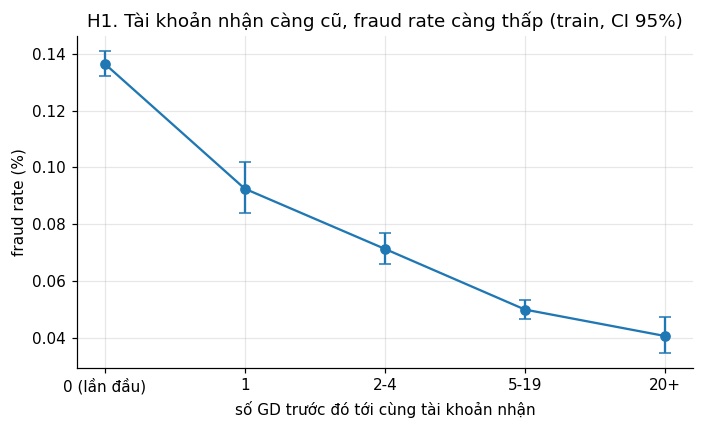

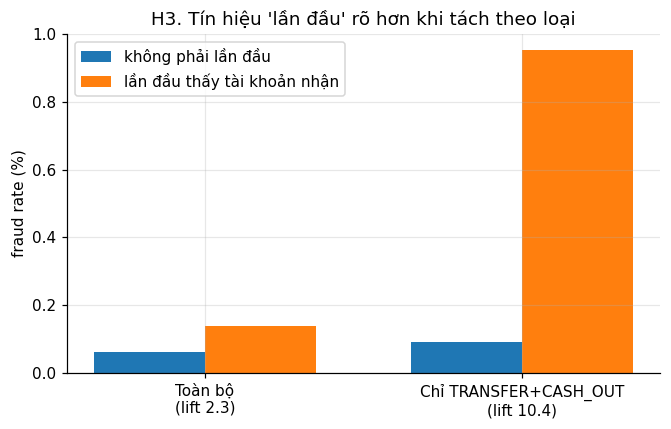

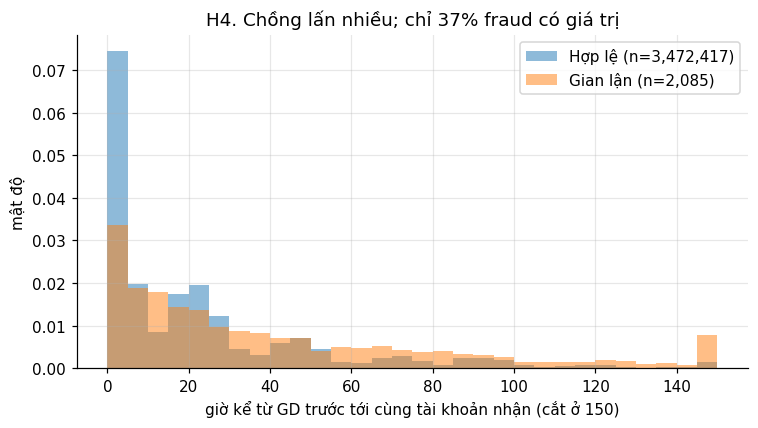

In [7]:
# ===== [4c] BIỂU ĐỒ: velocity có tín hiệu, 'lần đầu' bị loãng theo loại, time-since-last chồng lấn =====
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})
FIG = OUT_DIR / "figs"; FIG.mkdir(exist_ok=True)
def done(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=200); plt.show()

# H1: fraud rate theo lịch sử tài khoản nhận (bảng g từ [4])
yv = g["fraud_rate_pct"].to_numpy(); xs = np.arange(len(g))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(xs, yv, yerr=[yv - g["ci_low_pct"].to_numpy(), g["ci_high_pct"].to_numpy() - yv], fmt="o-", capsize=4)
ax.set_xticks(xs, g.index.astype(str)); ax.set_xlabel("số GD trước đó tới cùng tài khoản nhận"); ax.set_ylabel("fraud rate (%)")
ax.set_title("H1. Tài khoản nhận càng cũ, fraud rate càng thấp (train, CI 95%)"); done("H1_velocity_signal")

# H3: dest_first_seen toàn bộ vs chỉ TRANSFER + CASH_OUT
m_tc = is_trn & df["type"].isin(["TRANSFER", "CASH_OUT"]).to_numpy()
rate_all = df.loc[is_trn, TARGET].groupby(cand.loc[is_trn, "dest_first_seen"]).mean() * 100
rate_tc = df.loc[m_tc, TARGET].groupby(cand.loc[m_tc, "dest_first_seen"]).mean() * 100
fig, ax = plt.subplots(figsize=(6.2, 4)); bw = .35; xs2 = np.arange(2)
ax.bar(xs2 - bw/2, [rate_all[0], rate_tc[0]], bw, label="không phải lần đầu")
ax.bar(xs2 + bw/2, [rate_all[1], rate_tc[1]], bw, label="lần đầu thấy tài khoản nhận")
ax.set_xticks(xs2, [f"Toàn bộ\n(lift {rate_all[1]/rate_all[0]:.1f})", f"Chỉ TRANSFER+CASH_OUT\n(lift {rate_tc[1]/rate_tc[0]:.1f})"])
ax.set_ylabel("fraud rate (%)"); ax.set_title("H3. Tín hiệu 'lần đầu' rõ hơn khi tách theo loại"); ax.legend(); done("H3_first_seen_by_type")

# H4: time-since-last, hai lớp chồng lấn
hv = pd.DataFrame({"h": cand.loc[is_trn, "hours_since_last_dest_tx"].to_numpy(), "y": y_all[is_trn]}).dropna()
bins = np.arange(0, 151, 5); fig, ax = plt.subplots(figsize=(7, 4))
for lab, name in ((0, "Hợp lệ"), (1, "Gian lận")):
    s = hv.loc[hv["y"] == lab, "h"].clip(upper=150); ax.hist(s, bins=bins, density=True, alpha=.5, label=f"{name} (n={len(s):,})")
ax.set_xlabel("giờ kể từ GD trước tới cùng tài khoản nhận (cắt ở 150)"); ax.set_ylabel("mật độ"); ax.legend()
ax.set_title(f"H4. Chồng lấn nhiều; chỉ {hv['y'].sum()/y_all[is_trn].sum():.0%} fraud có giá trị"); done("H4_time_since_last")

In [8]:
# ===== [5] CỜ RỦI RO SYNTHETIC + ĐIỂM GỘP =====
NEW_ACCOUNT_DAYS, LOW_TRUST, FAR_IP_KM, MANY_FAILED = 90, 0.4, 500, 3   # ngưỡng của từng cờ

flags = pd.DataFrame({
    "is_new_account":      (df["account_age_days"] < NEW_ACCOUNT_DAYS),
    "is_low_trust_device": (df["device_trust_score"] < LOW_TRUST),
    "is_far_ip":           (df["ip_billing_distance_km"] > FAR_IP_KM),
    "is_many_failed_auth": (df["failed_auth_attempts_24h"] >= MANY_FAILED),
    "is_new_device":       df["is_new_device"].astype(bool),
    "shipping_billing_mismatch": df["shipping_billing_mismatch"].astype(bool),
}).astype("int8")

df["n_risk_flags"] = flags.sum(axis=1).astype("int8")
df["log_ip_distance"] = np.log1p(df["ip_billing_distance_km"]).astype("float32")

# Kiểm tra 1: tỷ lệ mỗi cờ bật
print("Tỷ lệ mỗi cờ bật = 1:"); display(flags.mean().to_frame("share").T)

# Kiểm tra 2: phân phối điểm gộp
print("Phân phối n_risk_flags:"); display(df["n_risk_flags"].value_counts().sort_index().to_frame("rows"))

Tỷ lệ mỗi cờ bật = 1:


,is_new_account,is_low_trust_device,is_far_ip,is_many_failed_auth,is_new_device,shipping_billing_mismatch
share,0.0237,0.0049,0.0315,0.0012,0.0811,0.0508


Phân phối n_risk_flags:


,rows
n_risk_flags,
0,5235060
1,1044403
2,73657
3,4152
4,2761
5,2037
6,550


In [9]:
# ===== [6] CỜ RỦI RO CÓ LIÊN QUAN ĐẾN FRAUD KHÔNG? (chỉ train) =====
is_tr = (df["step"] <= SPLIT_STEPS[0]).to_numpy()
y = df.loc[is_tr, TARGET].to_numpy().astype(bool)
F = flags[is_tr]

rows = []
for c in F.columns:
    m = F[c].to_numpy().astype(bool)
    n1, k1, n0, k0 = m.sum(), y[m].sum(), (~m).sum(), y[~m].sum()
    lo, hi = wilson(k1, n1)
    rows.append({"flag": c, "n_with": n1, "fraud_rate_with_pct": 100*k1/n1, "ci_low_pct": 100*lo, "ci_high_pct": 100*hi,
                 "fraud_rate_without_pct": 100*k0/n0, "lift": (k1/n1)/max(k0/n0, 1e-12), "share_of_all_fraud_pct": 100*k1/y.sum()})
display(pd.DataFrame(rows).set_index("flag"))

b = df[is_tr].groupby("n_risk_flags")[TARGET].agg(transactions="size", fraud="sum")
b["fraud_rate_pct"] = 100 * b["fraud"] / b["transactions"]
print("Fraud rate theo điểm gộp n_risk_flags:"); display(b)

,n_with,fraud_rate_with_pct,ci_low_pct,ci_high_pct,fraud_rate_without_pct,lift,share_of_all_fraud_pct
flag,,,,,,,
is_new_account,142106,2.7339,2.6504,2.8199,0.0293,93.2593,69.1158
is_low_trust_device,27740,16.8962,16.4598,17.3417,0.0155,"1,091.9736",83.3837
is_far_ip,190038,1.5092,1.4553,1.5650,0.0469,32.2008,51.0229
is_many_failed_auth,6076,49.5063,48.2498,50.7633,0.0431,"1,147.7494",53.5136
is_new_device,489862,0.8227,0.7978,0.8484,0.0285,28.8232,71.6954
shipping_billing_mismatch,306729,1.1052,1.0688,1.1428,0.0388,28.5210,60.3096


Fraud rate theo điểm gộp n_risk_flags:


,transactions,fraud,fraud_rate_pct
n_risk_flags,,,
0,4991493,13,0.0003
1,995420,97,0.0097
2,70052,555,0.7923
3,3404,1310,38.4841
4,1900,1879,98.8947
5,1387,1387,100.0000
6,380,380,100.0000


In [10]:
# ===== [7] SỐ TIỀN, GIỜ, LOẠI GIAO DỊCH =====
ALL_TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]

df["hour_of_day"] = ((df["step"] - 1) % 24).astype("int8")      # step 1 = giờ 0
df["log_amount"] = np.log1p(df["amount"]).astype("float32")
for t in ALL_TYPES:
    df[f"type_{t}"] = (df["type"] == t).astype("int8")          # one-hot cố định 5 cột (DEBIT sẽ bị bỏ khi chọn feature)

# Kiểm tra 1: mỗi dòng đúng 1 cột type = 1
print("One-hot đúng (tổng = 1 mọi dòng):", bool((df[[f"type_{t}" for t in ALL_TYPES]].sum(axis=1) == 1).all()))

# Kiểm tra 2: hour_of_day nằm trong 0-23
print("hour_of_day:", df["hour_of_day"].min(), "-", df["hour_of_day"].max())

# Kiểm tra 3: fraud rate theo loại giao dịch và theo giờ (chỉ train)
tr = df[df["step"] <= SPLIT_STEPS[0]]
display(tr.groupby("type")[TARGET].agg(rows="size", fraud="sum").assign(fraud_rate_pct=lambda t: 100*t.fraud/t.rows))
display(tr.groupby("hour_of_day")[TARGET].agg(rows="size", fraud="sum").assign(fraud_rate_pct=lambda t: 100*t.fraud/t.rows).T)

One-hot đúng (tổng = 1 mọi dòng): True
hour_of_day: 0 - 23


,rows,fraud,fraud_rate_pct
type,,,
CASH_IN,1331163,0,0.0000
CASH_OUT,2141481,2820,0.1317
DEBIT,38991,0,0.0000
PAYMENT,2047519,0,0.0000
TRANSFER,504882,2801,0.5548


hour_of_day,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
rows,"24,157.0000","8,195.0000","1,462.0000","1,020.0000","1,237.0000","1,876.0000","8,834.0000","23,497.0000","274,332.0000","411,024.0000","434,911.0000","462,211.0000","444,752.0000","415,906.0000","404,163.0000","413,379.0000","432,447.0000","538,788.0000","624,921.0000","526,711.0000","231,057.0000","178,207.0000","132,904.0000","68,045.0000"
fraud,252.0000,248.0000,214.0000,190.0000,236.0000,238.0000,240.0000,238.0000,247.0000,255.0000,216.0000,233.0000,242.0000,251.0000,241.0000,229.0000,253.0000,241.0000,216.0000,248.0000,245.0000,233.0000,219.0000,196.0000
fraud_rate_pct,1.0432,3.0262,14.6375,18.6275,19.0784,12.6866,2.7168,1.0129,0.0900,0.0620,0.0497,0.0504,0.0544,0.0604,0.0596,0.0554,0.0585,0.0447,0.0346,0.0471,0.1060,0.1307,0.1648,0.2880


,n_with,fraud_rate_with_pct,ci_low_pct,ci_high_pct,fraud_rate_without_pct,lift,share_of_all_fraud_pct
flag,,,,,,,
is_new_account,142106,2.7339,2.6504,2.8199,0.0293,93.2593,69.1158
is_low_trust_device,27740,16.8962,16.4598,17.3417,0.0155,"1,091.9736",83.3837
is_far_ip,190038,1.5092,1.4553,1.5650,0.0469,32.2008,51.0229
is_many_failed_auth,6076,49.5063,48.2498,50.7633,0.0431,"1,147.7494",53.5136
is_new_device,489862,0.8227,0.7978,0.8484,0.0285,28.8232,71.6954
shipping_billing_mismatch,306729,1.1052,1.0688,1.1428,0.0388,28.5210,60.3096
dest_first_seen,2589534,0.1365,0.1321,0.1411,0.0600,2.2755,62.9070
amount_ge_1M,124900,1.4956,1.4298,1.5644,0.0632,23.6679,33.2325
amount_ge_5M,10934,4.4449,4.0743,4.8474,0.0848,52.3956,8.6461


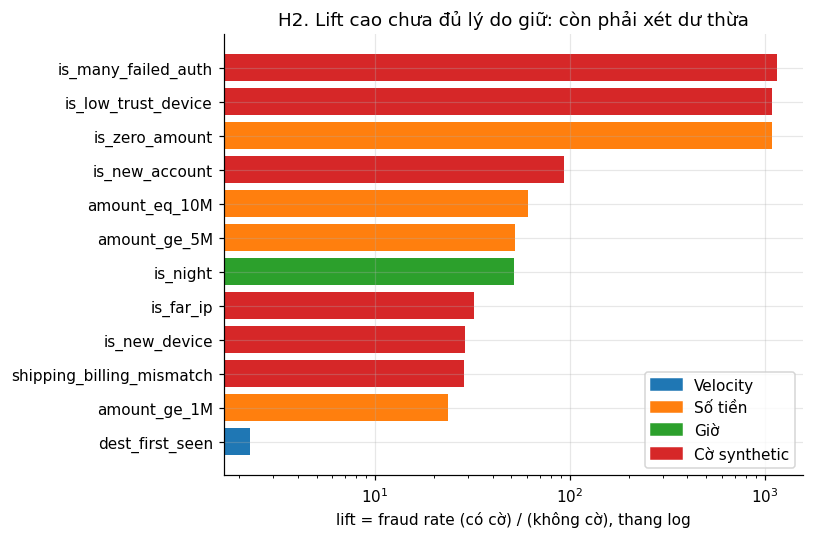

In [11]:
# ===== [7b] ỨNG VIÊN SỐ TIỀN / GIỜ + LIFT CỦA MỌI CỜ (chỉ train) =====
cand["amount_ge_1M"] = (df["amount"] >= 1_000_000).astype("int8"); cand["amount_ge_5M"] = (df["amount"] >= 5_000_000).astype("int8")
cand["amount_eq_10M"] = (df["amount"] == 10_000_000).astype("int8"); cand["amount_gt_10M"] = (df["amount"] > 10_000_000).astype("int8")
cand["is_night"] = df["hour_of_day"].between(0, 5).astype("int8")
cand["is_zero_amount"] = df["is_zero_amount"].astype("int8")
AMT_CANDS = ["amount_ge_1M", "amount_ge_5M", "amount_eq_10M", "amount_gt_10M", "is_night", "is_zero_amount"]
sig_amt = signal_table(cand, AMT_CANDS); sig_all = pd.concat([sig_vel, sig_amt])

def flag_table(F, y):
    out = []
    for c in F.columns:
        m = F[c].to_numpy().astype(bool); n1 = int(m.sum())
        if n1 == 0: continue
        k1 = int(y[m].sum()); n0 = int((~m).sum()); k0 = int(y[~m].sum()); lo, hi = wilson(k1, n1)
        out.append({"flag": c, "n_with": n1, "fraud_rate_with_pct": 100*k1/n1, "ci_low_pct": 100*lo, "ci_high_pct": 100*hi,
                    "fraud_rate_without_pct": 100*k0/n0, "lift": (k1/n1) / max(k0/n0, 1e-12), "share_of_all_fraud_pct": 100*k1/max(y.sum(), 1)})
    return pd.DataFrame(out).set_index("flag")

F_all = pd.concat([flags, cand[["dest_first_seen"] + AMT_CANDS]], axis=1).loc[is_trn]
lift_tab = flag_table(F_all, y_all[is_trn].astype(bool)); display(lift_tab)

# H2: lift theo nhóm tín hiệu
GROUP = {**{c: "Cờ synthetic" for c in flags.columns}, "dest_first_seen": "Velocity", "is_night": "Giờ",
         **{c: "Số tiền" for c in AMT_CANDS if c != "is_night"}}
COL = {"Velocity": "tab:blue", "Số tiền": "tab:orange", "Giờ": "tab:green", "Cờ synthetic": "tab:red"}
e = lift_tab.loc[lift_tab["lift"] > 0, "lift"].sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5)); ax.barh(e.index, e.values, color=[COL[GROUP[f]] for f in e.index]); ax.set_xscale("log")
ax.set_xlabel("lift = fraud rate (có cờ) / (không cờ), thang log")
ax.set_title("H2. Lift cao chưa đủ lý do giữ: còn phải xét dư thừa")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in COL.items()], loc="lower right"); done("H2_flag_lift")

In [12]:
# ===== [8] CHIA TẬP + amount_to_type_median + CHỐT FEATURES =====
FEATURES = ["log_amount", "amount_to_type_median", "is_amount_outlier_3xIQR", "hour_of_day",
            "type_CASH_IN", "type_CASH_OUT", "type_PAYMENT", "type_TRANSFER",   # DEBIT = loại tham chiếu, bỏ
            "dest_prior_tx_count",
            "n_risk_flags", "device_trust_score", "failed_auth_attempts_24h", "log_ip_distance", "account_age_days"]

raw_split = {"train": df[df["step"] <= SPLIT_STEPS[0]],
             "valid": df[(df["step"] > SPLIT_STEPS[0]) & (df["step"] <= SPLIT_STEPS[1])],
             "test":  df[df["step"] > SPLIT_STEPS[1]]}

# Median amount theo loại: CHỈ tính từ train, áp dụng cho cả 3 tập
med = raw_split["train"].groupby("type")["amount"].median().to_dict()
print("Median amount theo loại (từ train):"); display(pd.Series(med).to_frame("median"))

def add_ratio(x):
    x = x.copy()
    x["amount_to_type_median"] = (x["amount"] / x["type"].map(med)).astype("float32")
    return x

built = {k: add_ratio(v) for k, v in raw_split.items()}
tree = {k: v[FEATURES + [TARGET]].reset_index(drop=True) for k, v in built.items()}               # bản cho cây (chưa scale)
meta = {k: v[["step", "type", "amount"]].reset_index(drop=True) for k, v in built.items()}        # amount/step thô, cùng thứ tự dòng

# --- Kiểm tra
assert not (LEAKAGE & set(tree["train"].columns)), "Rò rỉ!"
assert all(len(tree[k]) == len(meta[k]) for k in tree), "meta lệch số dòng"
print("1) Cột giống nhau ở 3 tập:", all(list(tree[k].columns) == FEATURES + [TARGET] for k in tree))
print("2) NaN mỗi tập:", {k: int(v.isna().sum().sum()) for k, v in tree.items()}, "(phải toàn 0)")
print("3) Không còn inf:", all(np.isfinite(v[FEATURES].to_numpy(dtype=float)).all() for v in tree.values()))
sizes = pd.DataFrame({k: {"rows": len(v), "fraud": int(v[TARGET].sum()), "fraud_rate_pct": 100*v[TARGET].mean()} for k, v in tree.items()}).T
display(sizes)

Median amount theo loại (từ train):


,median
CASH_IN,"143,399.0400"
CASH_OUT,"147,357.5300"
DEBIT,"3,093.1300"
PAYMENT,"9,524.2800"
TRANSFER,"491,299.0950"


1) Cột giống nhau ở 3 tập: True
2) NaN mỗi tập: {'train': 0, 'valid': 0, 'test': 0} (phải toàn 0)
3) Không còn inf: True


,rows,fraud,fraud_rate_pct
train,"6,064,036.0000","5,621.0000",0.0927
valid,"208,896.0000","1,264.0000",0.6051
test,"89,688.0000","1,328.0000",1.4807


In [13]:
# ===== [9] BẢN SCALED CHO LOGISTIC REGRESSION =====
from sklearn.preprocessing import StandardScaler

SCALE_COLS = ["log_amount", "amount_to_type_median", "hour_of_day", "dest_prior_tx_count",
              "n_risk_flags", "device_trust_score", "failed_auth_attempts_24h", "log_ip_distance", "account_age_days"]
LOG_BEFORE_SCALE = ["amount_to_type_median", "dest_prior_tx_count"]     # đuôi dài -> log1p trước khi scale

def to_lr(x):
    x = x.copy(); x[LOG_BEFORE_SCALE] = np.log1p(x[LOG_BEFORE_SCALE]); return x

lr = {k: to_lr(v) for k, v in tree.items()}
scaler = StandardScaler().fit(lr["train"][SCALE_COLS])                   # fit CHỈ trên train
for k in lr:
    lr[k][SCALE_COLS] = scaler.transform(lr[k][SCALE_COLS])

# --- Kiểm tra
print("1) NaN (scaled):", {k: int(v.isna().sum().sum()) for k, v in lr.items()}, "(phải toàn 0)")
print("2) Cột nhị phân không bị scale (vẫn 0/1):",
      bool(lr["train"][["is_amount_outlier_3xIQR", "type_CASH_IN", "type_CASH_OUT", "type_PAYMENT", "type_TRANSFER"]].isin([0, 1]).all().all()))
chk = pd.DataFrame({"train_mean": lr["train"][SCALE_COLS].mean(), "train_std": lr["train"][SCALE_COLS].std(),
                    "valid_mean": lr["valid"][SCALE_COLS].mean(), "valid_std": lr["valid"][SCALE_COLS].std()})
print("3) Train phải có mean≈0, std≈1; valid lệch nhẹ là bình thường (KHÔNG fit lại trên valid):"); display(chk)

1) NaN (scaled): {'train': 0, 'valid': 0, 'test': 0} (phải toàn 0)
2) Cột nhị phân không bị scale (vẫn 0/1): True
3) Train phải có mean≈0, std≈1; valid lệch nhẹ là bình thường (KHÔNG fit lại trên valid):


,train_mean,train_std,valid_mean,valid_std
log_amount,0.0000,1.0000,-0.0604,1.0246
amount_to_type_median,-0.0000,1.0000,-0.0659,0.9901
hour_of_day,0.0000,1.0000,0.1568,1.0797
dest_prior_tx_count,-0.0000,1.0000,-0.0288,1.0069
n_risk_flags,-0.0000,1.0000,0.0454,1.1795
device_trust_score,0.0000,1.0000,-0.0220,1.0513
failed_auth_attempts_24h,0.0000,1.0000,0.0334,1.1450
log_ip_distance,0.0000,1.0000,0.0114,1.0178
account_age_days,-0.0000,1.0000,-0.0057,1.0037


In [14]:
# ===== [10] XỬ LÝ MẤT CÂN BẰNG (chỉ train) =====
from imblearn.over_sampling import SMOTENC

SMOTE_RATIO = 0.5
BIN_COLS = ["is_amount_outlier_3xIQR", "type_CASH_IN", "type_CASH_OUT", "type_PAYMENT", "type_TRANSFER"]
INT_COLS = ["hour_of_day", "dest_prior_tx_count", "n_risk_flags", "failed_auth_attempts_24h", "account_age_days"]

def smote_resample(frame, cols, ratio, seed, round_int=True):
    cat = [cols.index(c) for c in BIN_COLS if c in cols]
    Xs, ys = SMOTENC(categorical_features=cat, sampling_strategy=ratio, random_state=seed).fit_resample(
        frame[cols].to_numpy(), frame[TARGET].to_numpy())
    out = pd.DataFrame(Xs, columns=cols)
    if round_int:
        ic = [c for c in INT_COLS if c in cols]; out[ic] = out[ic].round()
    out[TARGET] = ys
    return out

def scale_for_lr(frame):                       # cùng pipeline với bản scaled của train/valid/test
    x = to_lr(frame); x[SCALE_COLS] = scaler.transform(x[SCALE_COLS]); return x

train = tree["train"]; pos = int(train[TARGET].sum()); neg = len(train) - pos

# 1) Undersample: giữ toàn bộ fraud, lấy ngẫu nhiên 10 hợp lệ / 1 fraud
legit = train[train[TARGET] == 0].sample(n=min(neg, pos * UNDER_RATIO), random_state=SEED)
under = (pd.concat([train[train[TARGET] == 1], legit])
           .sample(frac=1, random_state=SEED).reset_index(drop=True))

# 2) SMOTENC trên bản đã undersample (giữ cột nhị phân đúng 0/1)
smote = smote_resample(under, FEATURES, SMOTE_RATIO, SEED)
smote[FEATURES] = smote[FEATURES].astype(train[FEATURES].dtypes.to_dict())    # trả lại kiểu dữ liệu gốc

# 3) Bản scaled cho Logistic Regression (cùng scaler đã fit trên train gốc)
var = {"undersampled": under, "undersampled_scaled": scale_for_lr(under),
       "under_smote": smote, "under_smote_scaled": scale_for_lr(smote)}

# --- Kiểm tra
tab = pd.DataFrame({"rows": [len(train), len(under), len(smote)],
                    "fraud": [pos, int(under[TARGET].sum()), int(smote[TARGET].sum())]},
                   index=["train gốc", f"undersample {UNDER_RATIO}:1", f"undersample + SMOTENC ({SMOTE_RATIO})"])
tab["fraud_rate_pct"] = 100 * tab["fraud"] / tab["rows"]; display(tab)
print("Cột phân loại sau SMOTENC còn 0/1:", bool(smote[BIN_COLS].isin([0, 1]).all().all()))
print("NaN:", {n: int(v.isna().sum().sum()) for n, v in var.items()}, "(phải toàn 0)")
print("Cột bản scaled khớp:", all(list(v.columns) == FEATURES + [TARGET] for v in var.values()))

,rows,fraud,fraud_rate_pct
train gốc,6064036,5621,0.0927
undersample 10:1,61831,5621,9.0909
undersample + SMOTENC (0.5),84315,28105,33.3333


Cột phân loại sau SMOTENC còn 0/1: True
NaN: {'undersampled': 0, 'undersampled_scaled': 0, 'under_smote': 0, 'under_smote_scaled': 0} (phải toàn 0)
Cột bản scaled khớp: True


Drift (thang log1p, chỉ trên dòng có giá trị). Ngưỡng cảnh báo |drift| > 0.25:


,nan_train_pct,nan_valid_pct,train_mean,valid_mean,drift_std
feature,,,,,
dest_prior_tx_count,0.0000,0.0000,1.1254,1.0921,-0.0288
orig_prior_tx_count,0.0000,0.0000,0.0010,0.0020,0.0393
dest_first_seen,0.0000,0.0000,0.2960,0.3088,0.0373
dest_tx_same_day,0.0000,0.0000,0.3068,0.0122,-0.5066
hours_since_last_dest_tx,42.7031,44.5490,2.3517,4.8771,1.8077
dest_total_received_before_log,0.0000,0.0000,7.9676,7.7168,-0.0360
dest_tx_last_6h,0.0000,0.0000,0.2578,0.0089,-0.4762
dest_tx_last_24h,0.0000,0.0000,0.4650,0.0231,-0.6556


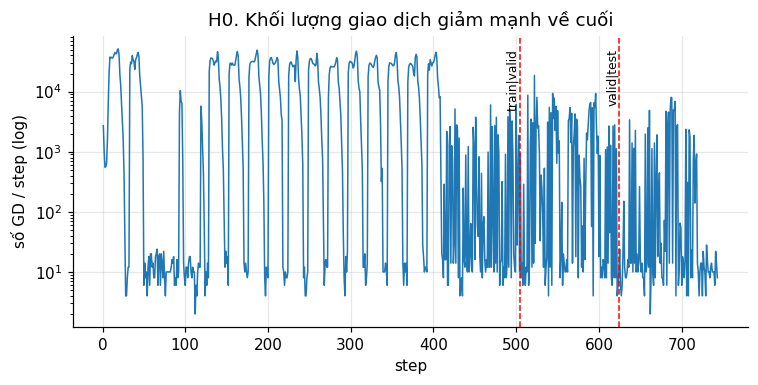

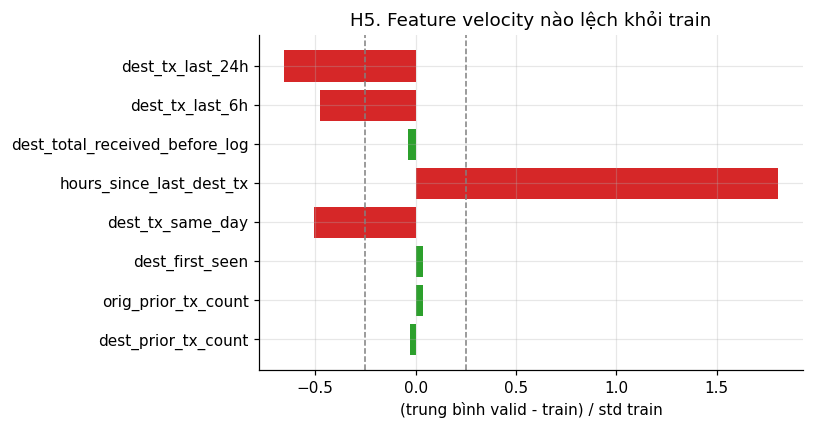

In [15]:
# ===== [10b] DRIFT: valid lệch khỏi train bao nhiêu độ lệch chuẩn của train? =====
is_val = ((df["step"] > SPLIT_STEPS[0]) & (df["step"] <= SPLIT_STEPS[1])).to_numpy()
ALREADY_LOG = {"dest_total_received_before_log"}                 # cột đã ở thang log, không log1p lần nữa
rows_ = []
for c in vel_cols:
    a = vel_frame.loc[is_trn, c].to_numpy("float64"); b_ = vel_frame.loc[is_val, c].to_numpy("float64")
    a_, b2 = a[~np.isnan(a)], b_[~np.isnan(b_)]
    if c not in ALREADY_LOG: a_, b2 = np.log1p(a_), np.log1p(b2)
    rows_.append({"feature": c, "nan_train_pct": 100*np.isnan(a).mean(), "nan_valid_pct": 100*np.isnan(b_).mean(),
                  "train_mean": a_.mean(), "valid_mean": b2.mean(), "drift_std": (b2.mean() - a_.mean()) / a_.std()})
drift = pd.DataFrame(rows_).set_index("feature"); DRIFT_THR = 0.25
print(f"Drift (thang log1p, chỉ trên dòng có giá trị). Ngưỡng cảnh báo |drift| > {DRIFT_THR}:"); display(drift)

# H0: khối lượng giao dịch theo step (nguyên nhân khả dĩ của drift ở feature đếm theo thời gian)
ps = df.groupby("step").size(); fig, ax = plt.subplots(figsize=(7, 3.6)); ax.plot(ps.index, ps.values, lw=1)
for s_, lab in ((SPLIT_STEPS[0], "train|valid"), (SPLIT_STEPS[1], "valid|test")):
    ax.axvline(s_, color="red", ls="--", lw=1); ax.text(s_, ps.max(), lab, rotation=90, va="top", ha="right", fontsize=8)
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("số GD / step (log)"); ax.set_title("H0. Khối lượng giao dịch giảm mạnh về cuối"); done("H0_volume_per_step")

# H5: drift của từng feature velocity
d5 = drift["drift_std"]; fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(d5.index, d5.values, color=["tab:green" if abs(v) < DRIFT_THR else "tab:red" for v in d5.values])
for r in (-DRIFT_THR, DRIFT_THR): ax.axvline(r, color="gray", ls="--", lw=1)
ax.set_xlabel("(trung bình valid - train) / std train"); ax.set_title("H5. Feature velocity nào lệch khỏi train"); done("H5_velocity_drift")

Khối 1: bộ 9 feature dữ liệu gốc (con số đáng tin). Δ = PR-AUC biến thể - cơ sở, cùng mẫu undersample:


,PR_AUC_mean,PR_AUC_std,delta_mean,delta_std,seeds_tăng,PR_AUC_thay_đổi
Cơ sở: 9 feature dữ liệu gốc,0.5686,0.0192,0.0000,0.0000,0,cơ sở
Bỏ dest_prior_tx_count,0.3813,0.0174,-0.1872,0.0093,0,giảm
Bỏ hour_of_day,0.4422,0.0055,-0.1264,0.0184,0,giảm
+ orig_prior_tx_count,0.5676,0.0121,-0.0010,0.0133,2,không rõ
+ dest_first_seen,0.5686,0.0192,0.0000,0.0000,1,không rõ
+ dest_tx_same_day,0.5239,0.0390,-0.0447,0.0198,0,giảm
+ hours_since_last_dest_tx,0.4823,0.0547,-0.0863,0.0356,0,giảm
+ dest_total_received_before_log,0.5558,0.0167,-0.0128,0.0058,0,giảm
+ dest_tx_last_6h,0.5240,0.0240,-0.0446,0.0061,0,giảm
+ dest_tx_last_24h,0.5254,0.0162,-0.0432,0.0077,0,giảm


Khối 2: bộ 14 feature (synthetic chi phối, PR-AUC ~ 1 nên khó thấy khác biệt):


,PR_AUC_mean,PR_AUC_std,delta_mean,delta_std,seeds_tăng,PR_AUC_thay_đổi
Cơ sở: 14 feature cuối,0.9985,0.0002,0.0000,0.0000,0,cơ sở
+ 7 cờ synthetic lẻ,0.9985,0.0004,0.0000,0.0002,1,không rõ


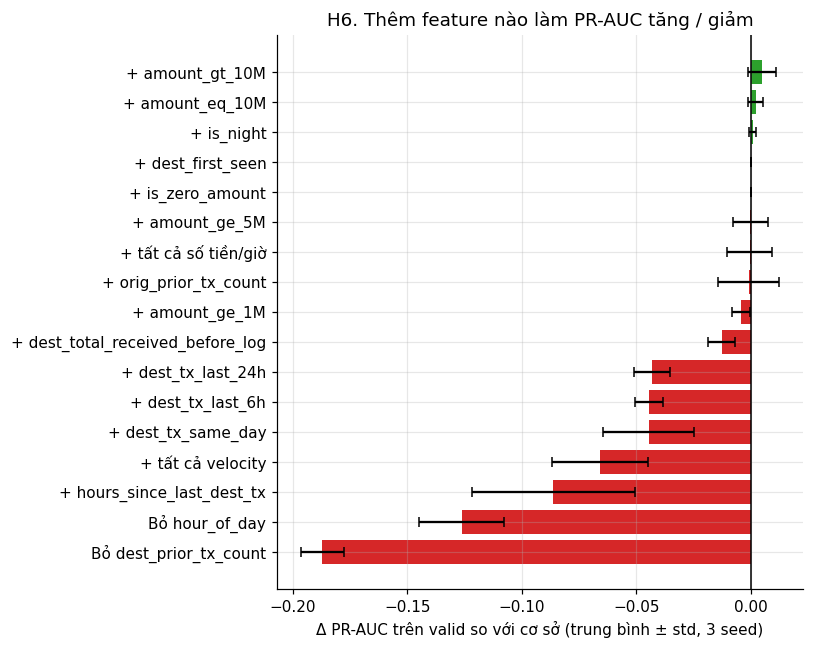

In [16]:
# ===== [10c] ABLATION: thêm TỪNG ứng viên vào bộ 9 feature dữ liệu gốc (undersample 10:1, valid) =====
import lightgbm as lgb
from sklearn.metrics import average_precision_score
TELEMETRY = ["n_risk_flags", "device_trust_score", "failed_auth_attempts_24h", "log_ip_distance", "account_age_days"]
DIAG = [f for f in FEATURES if f not in TELEMETRY]              # 9 feature không phụ thuộc synthetic
FLAG_CANDS = list(flags.columns) + ["new_device_and_mismatch"]
extra = pd.concat([cand, flags], axis=1); extra["new_device_and_mismatch"] = (flags["is_new_device"] & flags["shipping_billing_mismatch"]).astype("int8")

ev_tr = pd.concat([tree["train"], extra.loc[is_trn].reset_index(drop=True)], axis=1)       # cùng thứ tự dòng với tree[...]
ev_va = pd.concat([tree["valid"], extra.loc[is_val].reset_index(drop=True)], axis=1)
assert np.array_equal(ev_tr[TARGET].to_numpy(), y_all[is_trn]) and np.array_equal(ev_va[TARGET].to_numpy(), y_all[is_val]), "lệch thứ tự dòng"

SEEDS = (1, 2, 3)
pos_idx = np.flatnonzero(ev_tr[TARGET].to_numpy() == 1); neg_idx = np.flatnonzero(ev_tr[TARGET].to_numpy() == 0)
idx_by_seed = {s: np.concatenate([pos_idx, np.random.default_rng(s).choice(neg_idx, len(pos_idx) * UNDER_RATIO, replace=False)]) for s in SEEDS}

def fit_score(idx, cols):
    d_ = ev_tr.iloc[idx]
    m = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.1, random_state=SEED, verbose=-1, n_jobs=-1).fit(d_[cols], d_[TARGET])
    return average_precision_score(ev_va[TARGET], m.predict_proba(ev_va[cols])[:, 1])

def run_variants(variants, base):
    piv = pd.DataFrame({n: [fit_score(idx_by_seed[s], c) for s in SEEDS] for n, c in variants.items()}, index=[f"seed{s}" for s in SEEDS]).T
    delta = piv.sub(piv.loc[base], axis=1)                      # CÙNG mẫu undersample cho mọi biến thể => so sánh ghép cặp
    out = pd.DataFrame({"PR_AUC_mean": piv.mean(axis=1), "PR_AUC_std": piv.std(axis=1), "delta_mean": delta.mean(axis=1),
                        "delta_std": delta.std(axis=1), "seeds_tăng": (delta > 0).sum(axis=1)})
    def lab(r):
        if r.name == base: return "cơ sở"
        if r.seeds_tăng == len(SEEDS) and r.delta_mean > 0.01: return "tăng"
        if r.seeds_tăng == 0 and r.delta_mean < -0.01: return "giảm"
        return "không rõ"
    out["PR_AUC_thay_đổi"] = out.apply(lab, axis=1); return out

BASE = "Cơ sở: 9 feature dữ liệu gốc"
V = {BASE: DIAG,
     "Bỏ dest_prior_tx_count": [f for f in DIAG if f != "dest_prior_tx_count"],
     "Bỏ hour_of_day": [f for f in DIAG if f != "hour_of_day"]}
V.update({f"+ {c}": DIAG + [c] for c in VEL_CANDS + AMT_CANDS})
V["+ tất cả velocity"] = DIAG + VEL_CANDS
V["+ tất cả số tiền/giờ"] = DIAG + AMT_CANDS
abl_diag = run_variants(V, BASE)
print("Khối 1: bộ 9 feature dữ liệu gốc (con số đáng tin). Δ = PR-AUC biến thể - cơ sở, cùng mẫu undersample:"); display(abl_diag)

BASE2 = "Cơ sở: 14 feature cuối"
abl_syn = run_variants({BASE2: FEATURES, "+ 7 cờ synthetic lẻ": FEATURES + FLAG_CANDS}, BASE2)
print("Khối 2: bộ 14 feature (synthetic chi phối, PR-AUC ~ 1 nên khó thấy khác biệt):"); display(abl_syn)

# H6
a6 = abl_diag.drop(BASE).sort_values("delta_mean"); fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(a6.index, a6["delta_mean"], xerr=a6["delta_std"], capsize=3, color=["tab:red" if v < 0 else "tab:green" for v in a6["delta_mean"]])
ax.axvline(0, color="k", lw=1); ax.set_xlabel("Δ PR-AUC trên valid so với cơ sở (trung bình ± std, 3 seed)")
ax.set_title("H6. Thêm feature nào làm PR-AUC tăng / giảm"); done("H6_ablation_delta")

In [17]:
# ===== [10d] BẢNG QUYẾT ĐỊNH: gom bằng chứng, tự gắn lý do theo quy tắc =====
rows_ = []
for c in ["dest_prior_tx_count"] + VEL_CANDS + AMT_CANDS:
    grp = "Velocity" if c in vel_cols else ("Giờ" if c == "is_night" else "Số tiền")
    s = sig_all.loc[c]; dr = drift["drift_std"].get(c, np.nan); cov = s["coverage_pct"]
    lab = abl_diag["PR_AUC_thay_đổi"].get(f"+ {c}", "không áp dụng (đang giữ)")
    dlt = abl_diag["delta_mean"].get(f"+ {c}", abl_diag["delta_mean"].get("Bỏ dest_prior_tx_count") if c == "dest_prior_tx_count" else np.nan)
    why = []
    if c != "dest_prior_tx_count":
        if abs(dr) > DRIFT_THR: why.append(f"drift {dr:+.2f} std")
        if lab == "giảm": why.append("thêm vào làm PR-AUC giảm")
        elif lab == "không rõ": why.append("thêm vào không cải thiện PR-AUC")
        if cov < 80: why.append(f"chỉ phủ {cov:.0f}% GD")
        if c in maxcorr.index and maxcorr[c] > 0.95: why.append(f"|corr| {maxcorr[c]:.3f} với {cm_off[c].idxmax()}")
        if c == "dest_first_seen": why.append("là hàm của dest_prior_tx_count (== 0)")
        if c == "orig_prior_tx_count": why.append(f"{orig_single_share:.2%} tài khoản gửi chỉ dùng 1 lần")
    rows_.append({"nhóm": grp, "feature": c, "AUC_đơn_biến": s["AUC_đơn_biến"], "coverage_pct": cov, "drift_std": dr,
                  "Δ_PR_AUC": dlt, "kiểm_chứng": lab, "quyết_định": "GIỮ" if c == "dest_prior_tx_count" else ("LOẠI" if why else "XEM LẠI"),
                  "lý_do_tự_động": "; ".join(why) if why else "(không có lý do nào kích hoạt: cần xem lại)"})
decision = pd.DataFrame(rows_).set_index("feature"); display(decision)

EVID = OUT_DIR / "evidence"; EVID.mkdir(exist_ok=True)
for name, d_ in {"decision": decision, "signal": sig_all, "drift": drift, "lift": lift_tab, "ablation_diag": abl_diag, "ablation_synth": abl_syn}.items():
    d_.to_csv(EVID / f"{name}.csv")
print("Đã lưu bảng bằng chứng vào", EVID)

,nhóm,AUC_đơn_biến,coverage_pct,drift_std,Δ_PR_AUC,kiểm_chứng,quyết_định,lý_do_tự_động
feature,,,,,,,,
dest_prior_tx_count,Velocity,0.3827,100.0000,-0.0288,-0.1872,không áp dụng (đang giữ),GIỮ,(không có lý do nào kích hoạt: cần xem lại)
orig_prior_tx_count,Velocity,0.5005,100.0000,0.0393,-0.0010,không rõ,LOẠI,thêm vào không cải thiện PR-AUC; 99.85% tài kh...
dest_first_seen,Velocity,0.6011,100.0000,0.0373,0.0000,không rõ,LOẠI,thêm vào không cải thiện PR-AUC; |corr| 0.988 ...
dest_tx_same_day,Velocity,0.4032,100.0000,-0.5066,-0.0447,giảm,LOẠI,drift -0.51 std; thêm vào làm PR-AUC giảm
hours_since_last_dest_tx,Velocity,0.6465,57.2969,1.8077,-0.0863,giảm,LOẠI,drift +1.81 std; thêm vào làm PR-AUC giảm; chỉ...
dest_total_received_before_log,Velocity,0.3802,100.0000,-0.0360,-0.0128,giảm,LOẠI,thêm vào làm PR-AUC giảm; |corr| 0.988 với des...
dest_tx_last_6h,Velocity,0.4160,100.0000,-0.4762,-0.0446,giảm,LOẠI,drift -0.48 std; thêm vào làm PR-AUC giảm
dest_tx_last_24h,Velocity,0.3886,100.0000,-0.6556,-0.0432,giảm,LOẠI,drift -0.66 std; thêm vào làm PR-AUC giảm
amount_ge_1M,Số tiền,0.6560,100.0000,NaN,-0.0043,không rõ,LOẠI,thêm vào không cải thiện PR-AUC


Đã lưu bảng bằng chứng vào /kaggle/working/fe_out/evidence


In [18]:
# ===== [11] LƯU FILE BÀN GIAO =====
import joblib

for k in tree:
    tree[k].to_parquet(OUT_DIR / f"02_{k}.parquet", index=False)
    lr[k].to_parquet(OUT_DIR / f"02_{k}_scaled.parquet", index=False)
    meta[k].to_parquet(OUT_DIR / f"02_{k}_meta.parquet", index=False)
for n, v in var.items():
    v.to_parquet(OUT_DIR / f"03_train_{n}.parquet", index=False)
joblib.dump(scaler, OUT_DIR / "02_scaler.joblib")

EXCLUDED_REASON = {
    "dest_tx_last_6h, dest_tx_last_24h": "đã xây dựng và đánh giá; drift -0.48/-0.66 std ở valid, PR-AUC giảm 0.569 -> 0.524-0.540",
    "hours_since_last_dest_tx": "tín hiệu yếu, drift mạnh ở valid; bỏ đi PR-AUC tăng 0.517 -> 0.564",
    "dest_tx_same_day": "drift mạnh ở valid",
    "dest_total_received_before_log": "tương quan 0.988 với dest_first_seen",
    "dest_first_seen": "trùng dest_prior_tx_count == 0",
    "orig_prior_tx_count": "99.85% tài khoản gửi chỉ dùng 1 lần",
    "amount_ge_1M / ge_5M / eq_10M / gt_10M": "dư thừa với log_amount",
    "is_night, is_zero_amount, type_DEBIT": "độ quan trọng ~ 0",
    "các cờ synthetic lẻ": "đã gộp trong n_risk_flags"}
KNOWN_LIMITATIONS = [
    "5 feature synthetic (n_risk_flags, device_trust_score, failed_auth_attempts_24h, log_ip_distance, account_age_days) được sinh phụ thuộc nhãn: PR-AUC ~0.998 không phản ánh hiệu năng thực. Bỏ 5 cột này để ra bản đối chứng (~0.57 với LightGBM).",
    "hour_of_day phản ánh khối lượng giao dịch của simulator; bỏ nó PR-AUC giảm ~0.12.",
    "Tỷ lệ fraud lệch mạnh giữa các tập (0.09% / 0.61% / 1.48%).",
    "Mọi quyết định chọn feature/xử lý mất cân bằng dựa trên valid; test chỉ chấm một lần ở cuối.",
    "SMOTENC là mẫu tổng hợp, có thể không nhất quán nội bộ.",
    "Thứ tự giao dịch trong cùng 1 step = thứ tự file, không tái lập được ở thời gian thực."]
SERVING_NOTES = [
    "API nhận: step, type, amount, nameDest, account_age_days, device_trust_score, is_new_device, ip_billing_distance_km, shipping_billing_mismatch, failed_auth_attempts_24h, is_amount_outlier_3xIQR.",
    "dest_prior_tx_count cần bộ đếm theo nameDest, khởi tạo từ lịch sử trước đó.",
    "Median theo loại và ngưỡng cờ nằm trong final_features.json; scaler chỉ dùng cho Logistic Regression."]
json.dump({"features": FEATURES, "target": TARGET, "split_steps": list(SPLIT_STEPS),
           "amount_median_by_type": med,
           "risk_flag_thresholds": {"new_account_days": NEW_ACCOUNT_DAYS, "low_trust": LOW_TRUST,
                                    "far_ip_km": FAR_IP_KM, "many_failed_auth": MANY_FAILED},
           "scale_cols": SCALE_COLS, "log_before_scale": LOG_BEFORE_SCALE,
           "imbalance": {"chosen": f"undersample {UNDER_RATIO}:1", "smote_ratio": SMOTE_RATIO,
                         "note": "xác suất trên bản resample bị thổi phồng: chọn ngưỡng trên valid, không dùng 0.5"},
           "excluded_reason": EXCLUDED_REASON, "known_limitations": KNOWN_LIMITATIONS, "serving_notes": SERVING_NOTES},
          open(OUT_DIR / "final_features.json", "w"), indent=2, ensure_ascii=False)

for p in sorted(OUT_DIR.glob("*")): print(f"  {p.name:<42} {p.stat().st_size/1e6:9.1f} MB")

  02_scaler.joblib                                 0.0 MB
  02_test.parquet                                  2.8 MB
  02_test_meta.parquet                             0.7 MB
  02_test_scaled.parquet                           3.9 MB
  02_train.parquet                               152.3 MB
  02_train_meta.parquet                           39.8 MB
  02_train_scaled.parquet                        219.8 MB
  02_valid.parquet                                 6.4 MB
  02_valid_meta.parquet                            1.6 MB
  02_valid_scaled.parquet                          8.4 MB
  03_train_under_smote.parquet                     2.7 MB
  03_train_under_smote_scaled.parquet              3.7 MB
  03_train_undersampled.parquet                    2.0 MB
  03_train_undersampled_scaled.parquet             2.7 MB
  evidence                                         0.0 MB
  figs                                             0.0 MB
  final_features.json                              0.0 MB


In [19]:
# ===== [12] BỔ SUNG final_features.json: ngưỡng 3xIQR cho API + hướng dẫn xử lý mất cân bằng =====
q = df.groupby("type")["amount"].quantile([0.25, 0.75]).unstack()
fences = (q[0.75] + 3 * (q[0.75] - q[0.25])).to_dict()          # khớp Module 3: Q3 + 3*IQR theo từng loại

with open(OUT_DIR / "final_features.json", encoding="utf-8") as f:
    cfg = json.load(f)

cfg["outlier_fence_3xIQR_by_type"] = {k: round(float(v), 2) for k, v in fences.items()}
cfg["imbalance"]["files"] = {
    "cho cây": ["03_train_undersampled.parquet", "03_train_under_smote.parquet"],
    "cho Logistic Regression (đã scale)": ["03_train_undersampled_scaled.parquet", "03_train_under_smote_scaled.parquet"]}
cfg["imbalance"]["notes"] = [
    "LightGBM/XGBoost: không dùng class weight đầy đủ (~1.078 lần, PR-AUC kém hẳn); dùng bản undersample.",
    "Logistic Regression: class_weight='balanced' trên 02_train_scaled.parquet hoặc bản undersample đã scale cho kết quả ngang nhau.",
    "SMOTENC không cho lợi ích rõ rệt so với undersample (chênh lệch trong độ nhiễu)."]
cfg["serving_notes"] = [s for s in cfg["serving_notes"] if not s.startswith("API nhận")] + [
    "API nhận: step, type, amount, nameDest, account_age_days, device_trust_score, is_new_device, ip_billing_distance_km, shipping_billing_mismatch, failed_auth_attempts_24h.",
    "API tự tính is_amount_outlier_3xIQR = 1 nếu amount > outlier_fence_3xIQR_by_type[type]."]

with open(OUT_DIR / "final_features.json", "w", encoding="utf-8") as f:
    json.dump(cfg, f, indent=2, ensure_ascii=False)
print(cfg["outlier_fence_3xIQR_by_type"])

{'CASH_IN': 748065.8, 'CASH_OUT': 768148.96, 'DEBIT': 17416.16, 'PAYMENT': 57093.42, 'TRANSFER': 3252115.95}
